# Học kết hợp tuần tự (Boosting: AdaBoost & Gradient Boosting)

Khác với Bagging (Random Forest) huấn luyện các cây song song và độc lập, **Boosting** huấn luyện các cây **tuần tự**. Cây phía sau sinh ra để sửa chữa sai lầm của cây phía trước.

**1. AdaBoost (Adaptive Boosting):**
*   **Mô hình cơ sở (Weak Learner):** Thường sử dụng "Decision Stump" (Cây quyết định bị còi cọc, chỉ có độ sâu = 1, tức là chỉ 1 câu hỏi Yes/No).
*   **Đánh trọng số dữ liệu:** Ban đầu, mọi điểm dữ liệu có trọng số bằng nhau. Nếu cây $m$ phân loại sai một điểm, trọng số của điểm đó sẽ được **tăng lên**. Cây $m+1$ sẽ buộc phải chú ý nhiều hơn vào các điểm khó này.
*   **Đánh trọng số mô hình ($\alpha$):** Mỗi cây sẽ có một tiếng nói (trọng lượng) vào kết quả cuối cùng. Cây nào có tỷ lệ sai số nhỏ sẽ có tiếng nói lớn, tính bằng công thức: $\alpha_m = \frac{1}{2} \ln \left( \frac{1 - \epsilon_m}{\epsilon_m} \right)$
*   **Cập nhật trọng số:** $w_i^{(m+1)} = w_i^{(m)} \exp(-\alpha_m y_i \hat{y}_i)$ (với $y \in \{-1, 1\}$)

**2. Gradient Boosting:**
*   Thay vì điều chỉnh trọng số của dữ liệu, Gradient Boosting huấn luyện cây $m+1$ để dự đoán trực tiếp **phần dư (Residual Error)** của cây $m$.
*   Bản chất toán học là tối ưu hóa Gradient Descent trong không gian hàm (Function Space). Cây mới được fit vào negative gradient của Loss Function.

In [1]:
import numpy as np

class DecisionStump:
    """Cây quyết định độ sâu 1 (Gốc cây) dùng làm Weak Learner."""
    def __init__(self):
        self.polarity = 1
        self.feature_idx = None
        self.threshold = None
        self.alpha = None

    def predict(self, X):
        n_samples = X.shape[0]
        X_column = X[:, self.feature_idx]
        predictions = np.ones(n_samples)
        if self.polarity == 1:
            predictions[X_column < self.threshold] = -1
        else:
            predictions[X_column > self.threshold] = -1
        return predictions

class AdaBoostScratch:
    """Thuật toán AdaBoost phân loại nhị phân."""
    def __init__(self, n_clf=50):
        self.n_clf = n_clf
        self.clfs = []

    def fit(self, X: np.ndarray, y: np.ndarray):
        n_samples, n_features = X.shape
        
        # 1. Khởi tạo trọng số dữ liệu đồng đều (1/N)
        w = np.full(n_samples, (1 / n_samples))
        
        # AdaBoost yêu cầu nhãn {-1, 1}
        y_ = np.where(y <= 0, -1, 1)

        for _ in range(self.n_clf):
            clf = DecisionStump()
            min_error = float('inf')

            # 2. Tìm Stump tốt nhất trên dữ liệu đã được đánh trọng số
            for feature_i in range(n_features):
                X_column = X[:, feature_i]
                thresholds = np.unique(X_column)
                
                for threshold in thresholds:
                    p = 1
                    predictions = np.ones(n_samples)
                    predictions[X_column < threshold] = -1
                    
                    # Tính tổng trọng số của các điểm bị phân loại sai
                    error = sum(w[y_ != predictions])

                    # Nếu lỗi > 50%, đảo ngược phân cực để lỗi < 50%
                    if error > 0.5:
                        error = 1 - error
                        p = -1

                    # Cập nhật Stump tốt nhất
                    if error < min_error:
                        clf.polarity = p
                        clf.threshold = threshold
                        clf.feature_idx = feature_i
                        min_error = error

            # 3. Tính trọng số của mô hình hiện tại (Alpha)
            EPS = 1e-10 # Tránh chia cho 0
            clf.alpha = 0.5 * np.log((1.0 - min_error + EPS) / (min_error + EPS))

            # 4. Cập nhật và chuẩn hóa trọng số cho dữ liệu
            predictions = clf.predict(X)
            w *= np.exp(-clf.alpha * y_ * predictions)
            w /= np.sum(w)

            self.clfs.append(clf)
        return self

    def predict(self, X: np.ndarray) -> np.ndarray:
        # Bầu chọn có trọng số từ tất cả các Stumps
        clf_preds = [clf.alpha * clf.predict(X) for clf in self.clfs]
        y_pred = np.sum(clf_preds, axis=0)
        return np.where(y_pred >= 0, 1, 0)

Metric               | Scratch         | Sklearn (Ada)  
-------------------------------------------------------
Accuracy Score       | 0.9000          | 0.9000         
Time (ms)            | 248.78          | 32.55          


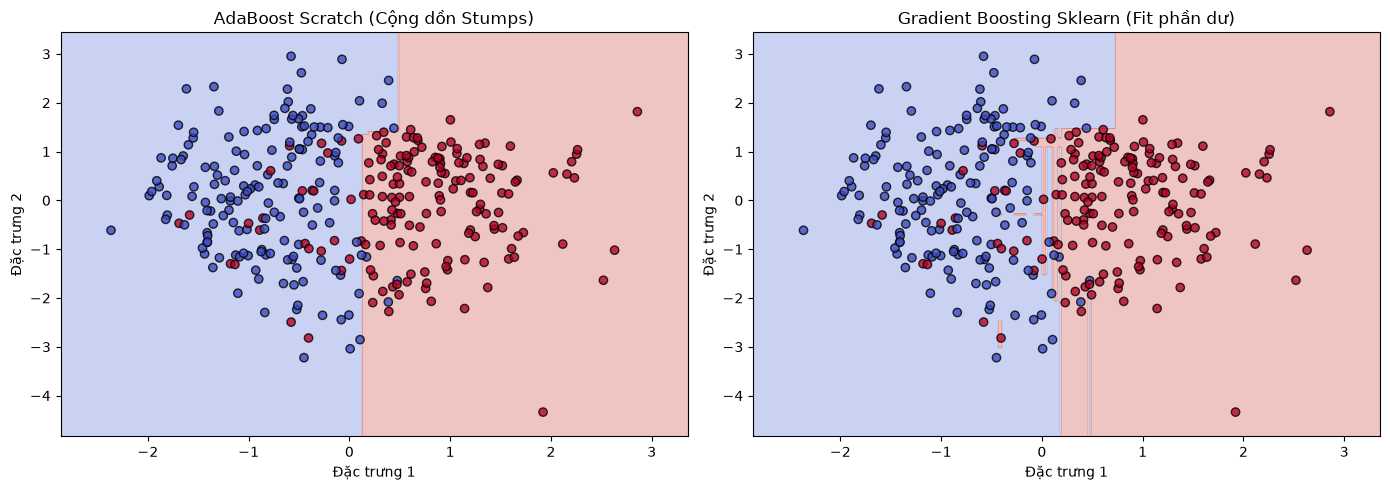

In [3]:
import time
import numpy as np
import matplotlib.pyplot as plt
from sklearn.ensemble import AdaBoostClassifier, GradientBoostingClassifier
from sklearn.datasets import make_classification
from utils.metrics import accuracy_score
from utils.preprocessing import train_test_split

# 1. Sinh dữ liệu
X, y = make_classification(n_samples=400, n_features=2, n_informative=2, 
                           n_redundant=0, n_classes=2, random_state=42, class_sep=0.8)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 2. Huấn luyện model Scratch (AdaBoost 30 Stumps)
t0 = time.time()
model_scratch = AdaBoostScratch(n_clf=30).fit(X_train, y_train)
t_scratch = (time.time() - t0) * 1000

# 3. Huấn luyện model Sklearn (AdaBoost và Gradient Boosting)
t0 = time.time()
# Dùng SAMME algorithm theo khuyến nghị mới của scikit-learn
# model_sklearn_ada = AdaBoostClassifier(n_estimators=30, algorithm="SAMME", random_state=42).fit(X_train, y_train) -> Dùng tham số SAMME algorithm nhưng các phiên bản scikit-learn mới nhất tham số algorithm đã bị loại bỏ hoàn toàn (thuật toán mặc định duy nhất được giữ lại và hệ thống không cho phép khai báo tham số này nữa để tránh dư thừa
model_sklearn_ada = AdaBoostClassifier(n_estimators=30, random_state=42).fit(X_train, y_train)
t_sklearn_ada = (time.time() - t0) * 1000

model_sklearn_gb = GradientBoostingClassifier(n_estimators=30, random_state=42).fit(X_train, y_train)

# 4. Đánh giá
y_pred_scratch = model_scratch.predict(X_test)
y_pred_sklearn_ada = model_sklearn_ada.predict(X_test)

print(f"{'Metric':<20} | {'Scratch':<15} | {'Sklearn (Ada)':<15}")
print("-" * 55)
print(f"{'Accuracy Score':<20} | {accuracy_score(y_test, y_pred_scratch):<15.4f} | {accuracy_score(y_test, y_pred_sklearn_ada):<15.4f}")
print(f"{'Time (ms)':<20} | {t_scratch:<15.2f} | {t_sklearn_ada:<15.2f}")

# 5. Trực quan hóa so sánh ranh giới
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
x_min, x_max = X_train[:, 0].min() - 0.5, X_train[:, 0].max() + 0.5
y_min, y_max = X_train[:, 1].min() - 0.5, X_train[:, 1].max() + 0.5
xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.02), np.arange(y_min, y_max, 0.02))

# Đồ thị 1: AdaBoost Scratch
Z_ada = model_scratch.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
ax1.contourf(xx, yy, Z_ada, alpha=0.3, cmap='coolwarm')
ax1.scatter(X_train[:, 0], X_train[:, 1], c=y_train, cmap='coolwarm', edgecolors='k', alpha=0.8)
ax1.set_title("AdaBoost Scratch (Cộng dồn Stumps)")
ax1.set_xlabel("Đặc trưng 1")
ax1.set_ylabel("Đặc trưng 2")

# Đồ thị 2: Gradient Boosting Sklearn
Z_gb = model_sklearn_gb.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
ax2.contourf(xx, yy, Z_gb, alpha=0.3, cmap='coolwarm')
ax2.scatter(X_train[:, 0], X_train[:, 1], c=y_train, cmap='coolwarm', edgecolors='k', alpha=0.8)
ax2.set_title("Gradient Boosting Sklearn (Fit phần dư)")
ax2.set_xlabel("Đặc trưng 1")
ax2.set_ylabel("Đặc trưng 2")

plt.tight_layout()
plt.show()